In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

## Data Collection

In [3]:
funds = ["FSPTX", "FSELX", "FSCSX", "FSPHX", "FBIOX", "FSMEX", "FPHAX", "FIDSX", "FSRBX", "FSPCX", "FSENX", "FSDAX", "FSRFX", "FSCPX", "FSAVX", "FSRPX", "FDFAX", "FSTCX", "FWRLX"]
prices = yf.download(tickers=funds + ["SPY", "XLK"], start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)

In [4]:
prices = prices["Adj Close"]
prices

Ticker,FBIOX,FDFAX,FIDSX,FPHAX,FSAVX,FSCPX,FSCSX,FSDAX,FSELX,FSENX,...,FSPCX,FSPHX,FSPTX,FSRBX,FSRFX,FSRPX,FSTCX,FWRLX,SPY,XLK
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,11.000015,46.551399,4.670525,10.712302,20.123478,19.435741,4.505635,6.041415,2.884585,36.330269,...,26.004520,10.029357,4.799391,11.604660,42.423233,4.205565,28.825594,3.914889,169.267548,18.041689
2015-01-05,11.020166,46.056793,4.580223,10.622028,19.604452,19.080355,4.434748,5.946350,2.837290,34.780521,...,25.517300,9.970016,4.720871,11.296419,41.462189,4.124608,28.381529,3.837536,166.210632,17.766270
2015-01-06,10.810782,45.965530,4.512496,10.556832,19.371326,18.899742,4.365808,5.905756,2.785574,34.280079,...,25.207952,9.872951,4.676362,11.035931,40.682724,4.080834,28.109367,3.798860,164.645126,17.552061
2015-01-07,11.174007,46.618637,4.551347,10.757435,19.718813,19.243483,4.386452,5.963821,2.811092,34.280079,...,25.455435,10.130101,4.708273,11.118417,40.833302,4.156614,28.276487,3.833238,166.696747,17.700699
2015-01-08,11.334734,47.358150,4.610148,10.963058,20.066298,19.523130,4.462013,6.089204,2.889348,35.038807,...,25.803444,10.312270,4.812408,11.292074,41.719051,4.208390,28.682358,3.893402,169.654770,18.089762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,29.000000,91.109657,16.469999,34.869999,51.939999,61.090000,24.660000,25.860001,63.730000,90.510002,...,91.459999,29.990000,58.070000,36.110001,112.410004,16.629999,67.925964,15.230000,767.179993,194.710007
2026-09-25,28.920000,91.507607,16.610001,35.000000,52.450001,61.259998,24.530001,26.059999,64.379997,89.889999,...,91.919998,29.959999,58.459999,36.509998,113.059998,16.719999,67.727005,15.320000,771.349976,196.270004
2026-09-28,28.969999,91.855804,16.410000,34.990002,51.380001,60.459999,24.299999,25.490000,63.840000,89.889999,...,91.730003,30.139999,57.889999,36.000000,112.720001,16.680000,66.851562,15.060000,765.609985,194.529999


In [5]:
log_returns = np.log(prices).diff().dropna()
market_log_returns = log_returns["SPY"]
xlk_log_returns = log_returns["XLK"]
log_returns = log_returns[funds]
print(log_returns)

Ticker         FSPTX     FSELX     FSCSX     FSPHX     FBIOX     FSMEX  \
Date                                                                     
2015-01-05 -0.016496 -0.016532 -0.015858 -0.005934  0.001830  0.003873   
2015-01-06 -0.009473 -0.018396 -0.015667 -0.009783 -0.019183 -0.008020   
2015-01-07  0.006801  0.009119  0.004717  0.025713  0.033046  0.019293   
2015-01-08  0.021876  0.027458  0.017079  0.017823  0.014281  0.018678   
2015-01-09 -0.005074  0.000942 -0.009472 -0.004426  0.000433 -0.004009   
...              ...       ...       ...       ...       ...       ...   
2026-09-24  0.000517 -0.004071 -0.005258  0.015119  0.004839  0.022781   
2026-09-25  0.006694  0.010148 -0.005286 -0.001001 -0.002762 -0.000176   
2026-09-28 -0.009798 -0.008423 -0.009421  0.005990  0.001727  0.010156   
2026-09-29 -0.004328  0.010285  0.001234 -0.001993 -0.003112  0.001914   
2026-09-30  0.005364  0.000465  0.011849 -0.007676 -0.001733 -0.008206   

Ticker         FPHAX     FIDSX     FS

## Performace Summary

### Part 1

In [6]:
mean_returns = log_returns.mean() * 252
volatilities = log_returns.std() * np.sqrt(252)
sharpe_ratio = mean_returns / volatilities

absolute = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
    "Sharpe Ratio": sharpe_ratio,
})

summary_abs = absolute.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_abs.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary_abs.round(4)

,Mean Return,Volatility,Sharpe Ratio
Min,0.0562,0.1482,0.2480
Q1,0.0826,0.1941,0.3823
Mean,0.1119,0.2263,0.4927
Median,0.0995,0.2181,0.4868
Q3,0.1158,0.2441,0.5612
Max,0.2653,0.3431,0.8405


### Part 2

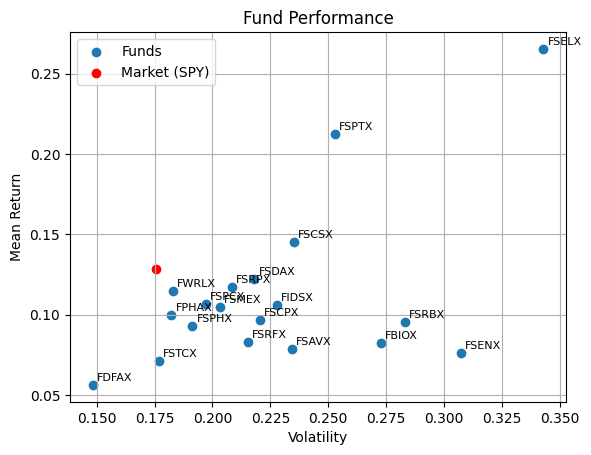

0.7313611469264726


,Mean Return,Volatility,Sharpe Ratio
Ticker,,,
FSPTX,0.212654,0.253010,0.840498
FSELX,0.265296,0.343075,0.773288
FSCSX,0.144971,0.235144,0.616521


In [7]:
market_mean_return = market_log_returns.mean() * 252
market_volatility = market_log_returns.std() * np.sqrt(252)

fund_metrics = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
})
plt.scatter(fund_metrics["Volatility"], fund_metrics["Mean Return"], label="Funds")
for t in fund_metrics.index:
    plt.annotate(t, (fund_metrics.loc[t, "Volatility"], fund_metrics.loc[t, "Mean Return"]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.scatter(market_volatility, market_mean_return, color="red", marker="o", label="Market (SPY)")
plt.xlabel("Volatility")
plt.ylabel("Mean Return")
plt.title("Fund Performance")
plt.grid(True)
plt.legend()
plt.show()

indices = fund_metrics["Mean Return"] > market_mean_return
outperforms_market = fund_metrics[indices].copy()
outperforms_market

market_sharpe_ratio = market_mean_return / market_volatility
print(market_sharpe_ratio)
outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]
outperforms_market

Only the three technology-oriented funds, Software (FSCSX, 14.5%), Technology (FSPTX, 21.3%) and Semiconductors (FSLX, 26.5%), outperform SPY's 12.9% mean return, but each does so with higher volatility (23.5%-34.3% vs. 17.6% for SPY).

### Part 3

#### (a)

In [8]:
combined = log_returns.copy()
combined["SPY"] = market_log_returns
covariances = combined.cov() * 252
betas = (covariances["SPY"] / covariances.loc["SPY", "SPY"]).drop("SPY")

alphas = mean_returns - betas * market_mean_return
alphas

treynor = (mean_returns) / betas
treynor

tracking_error = log_returns.sub(market_log_returns, axis=0)
tracking_error = tracking_error.std() * np.sqrt(252)

information_ratio = (mean_returns - market_mean_return) / tracking_error
information_ratio

relative = pd.DataFrame({
    "Jensen's Alpha": alphas,
    "Beta": betas,
    "Treynor Ratio": treynor,
    "Tracking Error": tracking_error,
    "Information Ratio": information_ratio,
})

summary = relative.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.062318,0.595045,0.071747,0.082447,-0.569804
Q1,-0.045769,0.878273,0.084866,0.123740,-0.298563
Mean,-0.016218,0.997018,0.110406,0.144635,-0.134738
Median,-0.015994,1.001509,0.109662,0.132159,-0.186634
Q3,-0.001411,1.107424,0.126945,0.142102,-0.136138
Max,0.064266,1.564427,0.169580,0.248289,0.682078


(b)

In [9]:
area = pd.Series({
    "FSPTX": "Technology", "FSELX": "Semiconductors", "FSCSX": "Software",
    "FSPHX": "Health Care", "FBIOX": "Biotechnology", "FSMEX": "Medical Technology",
    "FPHAX": "Pharmaceuticals", "FIDSX": "Financials", "FSRBX": "Banking",
    "FSPCX": "Insurance", "FSENX": "Energy", "FSDAX": "Aerospace/Defense",
    "FSRFX": "Transportation", "FSCPX": "Consumer Discretionary", "FSAVX": "Automotive",
    "FSRPX": "Retailing", "FDFAX": "Consumer Staples", "FSTCX": "Telecommunications",
    "FWRLX": "Wireless",
})

top5 = alphas.sort_values(ascending=False).index[:5]
top5_table = pd.concat([area[top5].rename("Area"), relative.loc[top5, ["Jensen's Alpha", "Beta"]], absolute.loc[top5]], axis=1)
top5_table["Mean Return Rank"] = mean_returns.rank(ascending=False)[top5].astype(int)
top5_table["Sharpe Rank"] = sharpe_ratio.rank(ascending=False)[top5].astype(int)
top5_table.round(4)

,Area,Jensen's Alpha,Beta,Mean Return,Volatility,Sharpe Ratio,Mean Return Rank,Sharpe Rank
Ticker,,,,,,,,
FSELX,Semiconductors,0.0643,1.5644,0.2653,0.3431,0.7733,1,2
FSPTX,Technology,0.0469,1.2903,0.2127,0.2530,0.8405,2,1
FPHAX,Pharmaceuticals,0.0096,0.6996,0.0995,0.1822,0.5459,10,7
FSDAX,Aerospace/Defense,-0.0004,0.9546,0.1223,0.2181,0.5605,4,6
FSCSX,Software,-0.0008,1.1342,0.1450,0.2351,0.6165,3,4


### 4.

#### (a)

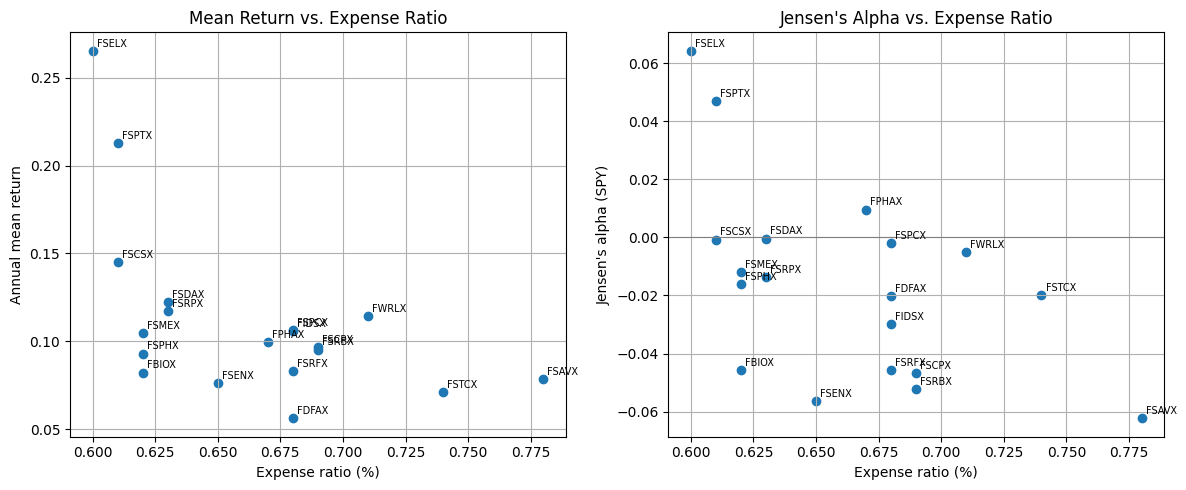

In [10]:
expense = pd.Series({
    "FSPTX": 0.61, "FSELX": 0.60, "FSCSX": 0.61, "FSPHX": 0.62, "FBIOX": 0.62,
    "FSMEX": 0.62, "FPHAX": 0.67, "FIDSX": 0.68, "FSRBX": 0.69, "FSPCX": 0.68,
    "FSENX": 0.65, "FSDAX": 0.63, "FSRFX": 0.68, "FSCPX": 0.69, "FSAVX": 0.78,
    "FSRPX": 0.63, "FDFAX": 0.68, "FSTCX": 0.74, "FWRLX": 0.71,
})

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(expense[funds], mean_returns[funds])
ax[0].set_xlabel("Expense ratio (%)")
ax[0].set_ylabel("Annual mean return")
ax[0].set_title("Mean Return vs. Expense Ratio")
ax[0].grid(True)

ax[1].scatter(expense[funds], alphas[funds])
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("Expense ratio (%)")
ax[1].set_ylabel("Jensen's alpha (SPY)")
ax[1].set_title("Jensen's Alpha vs. Expense Ratio")
ax[1].grid(True)

for t in funds:
    ax[0].annotate(t, (expense[t], mean_returns[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].annotate(t, (expense[t], alphas[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.savefig("fig_1_4.png", dpi=300)
plt.show()

#### (b)

In [11]:
print("Corr(ER, Mean): ", round(expense[funds].corr(mean_returns[funds]), 4))
print("Corr(ER, Alpha):", round(expense[funds].corr(alphas[funds]), 4))

Corr(ER, Mean):  -0.5501
Corr(ER, Alpha): -0.5391


### 5.

#### (a)

In [12]:
xlk_mean_return = xlk_log_returns.mean() * 252

returns_xlk = log_returns[funds].copy()
returns_xlk["XLK"] = xlk_log_returns
cov_xlk = returns_xlk.cov() * 252
betas_xlk = (cov_xlk["XLK"] / cov_xlk.loc["XLK", "XLK"]).drop("XLK")

alphas_xlk = mean_returns - betas_xlk * xlk_mean_return
treynor_xlk = mean_returns / betas_xlk
tracking_error_xlk = log_returns[funds].sub(xlk_log_returns, axis=0).std() * np.sqrt(252)
information_ratio_xlk = (mean_returns - xlk_mean_return) / tracking_error_xlk

relative_xlk = pd.DataFrame({
    "Jensen's Alpha": alphas_xlk,
    "Beta": betas_xlk,
    "Treynor Ratio": treynor_xlk,
    "Tracking Error": tracking_error_xlk,
    "Information Ratio": information_ratio_xlk,
})
summary_xlk = relative_xlk.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_xlk.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
display(summary_xlk.round(4))

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.0647,0.3177,0.1117,0.0596,-0.7486
Q1,-0.0329,0.5456,0.1466,0.1627,-0.6535
Mean,-0.0194,0.6449,0.1736,0.1845,-0.4806
Median,-0.0168,0.6089,0.1731,0.1838,-0.5125
Q3,-0.0020,0.6858,0.1934,0.2063,-0.4414
Max,0.0166,1.2688,0.2411,0.2976,0.3633


#### (b)

In [13]:
compare = pd.DataFrame({
    "Alpha_SPY": alphas[funds],
    "Rank_SPY": alphas[funds].rank(ascending=False).astype(int),
    "Alpha_XLK": alphas_xlk,
    "Rank_XLK": alphas_xlk.rank(ascending=False).astype(int),
}).sort_values("Rank_SPY")
display(compare.round(4))

,Alpha_SPY,Rank_SPY,Alpha_XLK,Rank_XLK
Ticker,,,,
FSELX,0.0643,1,0.0071,3
FSPTX,0.0469,2,0.0044,5
FPHAX,0.0096,3,0.0134,2
FSDAX,-0.0004,4,0.0061,4
FSCSX,-0.0008,5,-0.0292,13
FSPCX,-0.0020,6,0.0166,1
FWRLX,-0.0051,7,-0.0201,12
FSMEX,-0.0118,8,-0.0162,9
FSRPX,-0.0136,9,-0.0186,11


### Mean-Variance Efficient Frontier

#### 1. Monthly Data and Split

In [14]:
tickers_2 = ["FSPTX","FIDSX","FSCPX"]
prices_2 = yf.download(tickers=tickers_2, start="2015-01-01", end="2026-10-01", interval ="1mo", auto_adjust=False, progress=False)["Adj Close"][tickers_2]

log_returns_2 = np.log(prices_2).diff().dropna()

half = len(log_returns_2) // 2
r1 = log_returns_2.iloc[:half]
r2 = log_returns_2.iloc[half:]
print(len(r1), r1.index[0],r1.index[-1])
print(len(r2), r2.index[0],r2.index[-1])
returns_1 = r1
returns_2 = r2
print(returns_1)
print(returns_2)

70 2015-02-01 00:00:00 2020-11-01 00:00:00
70 2020-12-01 00:00:00 2026-09-01 00:00:00
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2015-02-01  0.068048  0.062110  0.077279
2015-03-01 -0.002818  0.000000 -0.004837
2015-04-01  0.012982  0.002024 -0.008784
2015-05-01  0.030156  0.014055  0.005568
2015-06-01 -0.027835 -0.009684  0.015082
...              ...       ...       ...
2020-07-01  0.071444  0.007547  0.065053
2020-08-01  0.116707  0.032062  0.086996
2020-09-01 -0.032826 -0.040873 -0.015778
2020-10-01 -0.038553  0.027433 -0.032146
2020-11-01  0.120733  0.162027  0.110556

[70 rows x 3 columns]
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2020-12-01  0.066881  0.078762  0.057194
2021-01-01  0.005197 -0.010875 -0.001814
2021-02-01  0.018342  0.112690  0.028789
2021-03-01 -0.001091  0.066147  0.034254
2021-04-01  0.031295  0.063721  0.065543
...              ...       ...       ...
2026-05-01  0.168246 -0.019343

#### 2. Mean Vectors

In [15]:
mu1 = r1.mean()
mu2 = r2.mean()
pd.DataFrame({"μ1 (monthly)": mu1, "μ2 (monthly)": mu2,
              "μ1 (annualized)": mu1 * 12, "μ2 (annualized)": mu2 * 12}).round(4)

,μ1 (monthly),μ2 (monthly),μ1 (annualized),μ2 (annualized)
Ticker,,,,
FSPTX,0.0193,0.0165,0.2310,0.1981
FIDSX,0.0063,0.0124,0.0750,0.1485
FSCPX,0.0115,0.0050,0.1377,0.0605


#### 3. Covariance Matrices

In [16]:
sigma1 = r1.std()
sigma2 = r2.std()
cov1 = r1.cov()
cov2 = r2.cov()
print("Standard Deviation (Period 1):", sigma1)
print("Standard Deviation (Period 2):", sigma2)
print("Covariance (Period 1):")
display(cov1.round(5))
print("Covariance (Period 2):")
display(cov2.round(5))
print("Variance (Period 1):")
print(np.diag(cov1))
print("Variance (Period 2):")
print(np.diag(cov2))
cov_FSPTX_FIDSX = cov1.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 1):", cov_FSPTX_FIDSX)
cov_FSPTX_FIDSX_2 = cov2.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 2):", cov_FSPTX_FIDSX_2)
cov_FSPTX_FSCPX = cov1.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 1):", cov_FSPTX_FSCPX)
cov_FSPTX_FSCPX_2 = cov2.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 2):", cov_FSPTX_FSCPX_2)
cov_FIDSX_FSCPX = cov1.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 1):", cov_FIDSX_FSCPX)
cov_FIDSX_FSCPX_2 = cov2.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 2):", cov_FIDSX_FSCPX_2)

# Standard deviations and variances as column vectors
display(pd.DataFrame({"Std Dev (P1)": sigma1, "Std Dev (P2)": sigma2,
                      "Variance (P1)": np.diag(cov1), "Variance (P2)": np.diag(cov2)}).round(5))

# Pairwise covariances as column vectors
pairs = [("FSPTX", "FIDSX"), ("FSPTX", "FSCPX"), ("FIDSX", "FSCPX")]
display(pd.DataFrame({
    "Cov (P1)": [cov1.loc[a, b] for a, b in pairs],
    "Cov (P2)": [cov2.loc[a, b] for a, b in pairs],
}, index=[f"{a}, {b}" for a, b in pairs]).round(5))


Standard Deviation (Period 1): Ticker
FSPTX    0.055841
FIDSX    0.060870
FSCPX    0.051879
dtype: float64
Standard Deviation (Period 2): Ticker
FSPTX    0.068836
FIDSX    0.056209
FSCPX    0.061107
dtype: float64
Covariance (Period 1):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00312,0.00237,0.00248
FIDSX,0.00237,0.00371,0.00258
FSCPX,0.00248,0.00258,0.00269


Covariance (Period 2):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00474,0.00156,0.00330
FIDSX,0.00156,0.00316,0.00218
FSCPX,0.00330,0.00218,0.00373


Variance (Period 1):
[0.00311822 0.00370512 0.00269146]
Variance (Period 2):
[0.00473846 0.00315943 0.00373408]
Covariance between FSPTX and FIDSX (Period 1): 0.002367677773564797
Covariance between FSPTX and FIDSX (Period 2): 0.00156275631413419
Covariance between FSPTX and FSCPX (Period 1): 0.00248110658351016
Covariance between FSPTX and FSCPX (Period 2): 0.0032995313976527264
Covariance between FIDSX and FSCPX (Period 1): 0.0025821554067418807
Covariance between FIDSX and FSCPX (Period 2): 0.002180783880187875


,Std Dev (P1),Std Dev (P2),Variance (P1),Variance (P2)
Ticker,,,,
FSPTX,0.05584,0.06884,0.00312,0.00474
FIDSX,0.06087,0.05621,0.00371,0.00316
FSCPX,0.05188,0.06111,0.00269,0.00373


,Cov (P1),Cov (P2)
"FSPTX, FIDSX",0.00237,0.00156
"FSPTX, FSCPX",0.00248,0.00330
"FIDSX, FSCPX",0.00258,0.00218


#### 4. The Two Funds

In [17]:
def two_funds(mu, Sigma):
    inv = np.linalg.inv(Sigma)
    ones = np.ones(len(mu))
    w0 = inv @ ones / (ones @ inv @ ones) #GMV portfolio weights
    w1 = inv @ mu - (ones @ inv @ mu) * w0
    return w0, w1

def mv_port(A, mu, sigma):
    w0, w1 = two_funds(mu, sigma)
    w = w0 + 1/A * w1
    return w

A_grid = np.arange(1, 101)
print(A_grid)

w0_1, w1_1 = two_funds(mu1.values, cov1.values)
w0_2, w1_2 = two_funds(mu2.values, cov2.values)

pd.DataFrame({"w0 (P1)": w0_1, "w1 (P1)": w1_1, "w0 (P2)": w0_2, "w1 (P2)": w1_2})

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]


,w0 (P1),w1 (P1),w0 (P2),w1 (P2)
0,0.248649,9.156072,0.294117,6.449325
1,0.089534,-4.208081,0.634793,3.363426
2,0.661818,-4.947992,0.071090,-9.812751


#### 5. Utopian MVEF

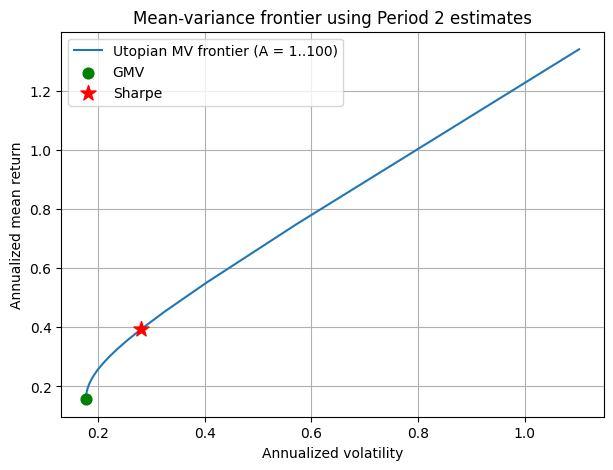

,GMV,Sharpe
w_FSPTX,0.2941,1.5870
w_FIDSX,0.6348,1.3091
w_FSCPX,0.0711,-1.8961
Ann. mean,0.1568,0.3941
Ann. vol,0.1773,0.2811
Ann. Sharpe,0.8845,1.4020
A,NaN,4.9882


In [18]:
def port_stats(w, mu, sigma):
    w = np.asarray(w)
    return w @ mu, np.sqrt(w @ sigma @ w)

mu2v, cov2v = mu2.values, cov2.values

#Utopian Frontier on the A grid
W5 = np.array([mv_port(A, mu2v, cov2v) for A in A_grid])
mean5 = W5 @ mu2v
vol5 = np.sqrt(np.einsum('ij,jk,ik->i', W5, cov2v, W5))

#GMV and Sharpe (tangency) portfolios, computed exactly
mean_gmv, vol_gmv = port_stats(w0_2, mu2v, cov2v)
A_T = np.ones(3) @ np.linalg.inv(cov2v) @ mu2v
w_T = mv_port(A_T, mu2v, cov2v)
mean_T, vol_T = port_stats(w_T, mu2v, cov2v)

#Plot (annualized: mean x12, vol x sqrt(12), applied to every series)
k_m, k_v = 12, np.sqrt(12)
plt.figure(figsize=(7, 5))
plt.plot(vol5*k_v, mean5*k_m, label="Utopian MV frontier (A = 1..100)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Mean-variance frontier using Period 2 estimates")
plt.grid(True); plt.legend()
plt.show()

# GMV and Sharpe portfolio summary (period 2, annualized)
pd.DataFrame({
    "GMV": list(w0_2) + [mean_gmv * k_m, vol_gmv * k_v, (mean_gmv * k_m) / (vol_gmv * k_v), np.nan],
    "Sharpe": list(w_T) + [mean_T * k_m, vol_T * k_v, (mean_T * k_m) / (vol_T * k_v), A_T],
}, index=["w_FSPTX", "w_FIDSX", "w_FSCPX", "Ann. mean", "Ann. vol", "Ann. Sharpe", "A"]).round(4)
    

#### 6. Realistic Out-of-Sample Evaluation

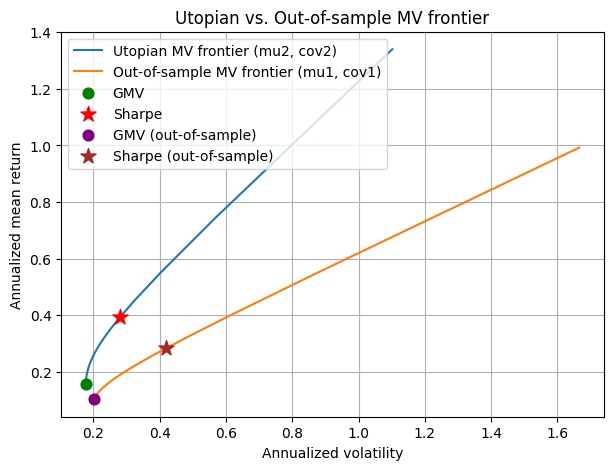

In [19]:
mu1v, cov1v = mu1.values, cov1.values

#build portfolios with period 1 estimates, evaluate them with period 2 estimates
W6 = np.array([mv_port(A, mu1v, cov1v) for A in A_grid])
mean6 = W6 @ mu2v
vol6 = np.sqrt(np.einsum('ij,jk,ik->i', W6, cov2v, W6))

#period-1 GMV and Sharpe portfolios, evaluated with period 2 estimates
mean_gmv1, vol_gmv1 = port_stats(w0_1, mu2v, cov2v)
A_T1 = np.ones(3) @ np.linalg.inv(cov1v) @ mu1v
w_T1 = mv_port(A_T1, mu1v, cov1v)
mean_T1, vol_T1 = port_stats(w_T1, mu2v, cov2v)

plt.figure(figsize=(7, 5))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian MV frontier (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample MV frontier (mu1, cov1)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.scatter(vol_gmv1*k_v, mean_gmv1*k_m, color="purple", s=60, zorder=3, label="GMV (out-of-sample)")
plt.scatter(vol_T1*k_v, mean_T1*k_m, color="brown", marker="*", s=130, zorder=3, label="Sharpe (out-of-sample)")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Utopian vs. Out-of-sample MV frontier")
plt.grid(True); plt.legend()
plt.show()

#### 7. Comparison of Utopian MV vs. Out-of-Sample MV

In [ ]:
inv2 = np.linalg.inv(cov2v); one = np.ones(3)
a, b, c = one @ inv2 @ one, one @ inv2 @ mu2v, mu2v @ inv2 @ mu2v
minvar = lambda mu: (a*mu**2 - 2*b*mu + c) / (a*c - b**2)

gap = vol6 - np.sqrt(minvar(mean6))
print("min gap (should be >= 0):", gap.min(), "| max gap:", gap.max())

min gap (should be >= 0): -0.9407749608376028 | max gap: -0.5191432902198615


#### 8. Parsimonious Build

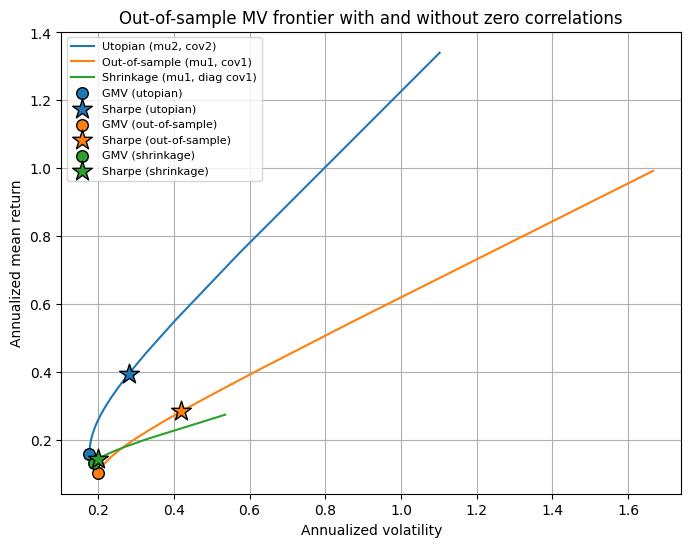

Vol 0.25: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.30: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.40: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.50: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325


,Ann. mean,Ann. vol,Ann. Sharpe
GMV (utopian),0.1568,0.1773,0.8845
Sharpe (utopian),0.3941,0.2811,1.4020
GMV (out-of-sample),0.1026,0.2010,0.5104
Sharpe (out-of-sample),0.2833,0.4198,0.6749
GMV (shrinkage),0.1311,0.1880,0.6971
Sharpe (shrinkage),0.1428,0.2010,0.7104


In [ ]:
mu1v, cov1v = mu1.values, cov1.values
cov1_diag = np.diag(np.diag(cov1v))  # zero correlations

def frontier(A_grid, mu_est, S_est, mu_eval, S_eval):
    W = np.array([mv_port(A, mu_est, S_est) for A in A_grid])
    return W @ mu_eval, np.sqrt(np.einsum("ij,jk,ik->i", W, S_eval, W))

mean6, vol6 = frontier(A_grid, mu1v, cov1v, mu2v, cov2v)       # Part 6 (out-of-sample)
mean8, vol8 = frontier(A_grid, mu1v, cov1_diag, mu2v, cov2v)   # Part 8 (shrinkage)

# GMV and Sharpe portfolios for each set of estimates, all evaluated in period 2
def gmv_and_sharpe(mu_est, S_est):
    w0, _ = two_funds(mu_est, S_est)
    A_T = np.ones(3) @ np.linalg.inv(S_est) @ mu_est
    wT = mv_port(A_T, mu_est, S_est)
    return port_stats(w0, mu2v, cov2v), port_stats(wT, mu2v, cov2v)

(m_g1, v_g1), (m_T1, v_T1) = gmv_and_sharpe(mu1v, cov1v)
(m_gd, v_gd), (m_Td, v_Td) = gmv_and_sharpe(mu1v, cov1_diag)

plt.figure(figsize=(8, 6))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample (mu1, cov1)")
plt.plot(vol8 * k_v, mean8 * k_m, color="tab:green", label="Shrinkage (mu1, diag cov1)")

plt.scatter(vol_gmv * k_v, mean_gmv * k_m, color="tab:blue", edgecolors="black", s=70, zorder=3, label="GMV (utopian)")
plt.scatter(vol_T * k_v, mean_T * k_m, color="tab:blue", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (utopian)")
plt.scatter(v_g1 * k_v, m_g1 * k_m, color="tab:orange", edgecolors="black", s=70, zorder=3, label="GMV (out-of-sample)")
plt.scatter(v_T1 * k_v, m_T1 * k_m, color="tab:orange", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (out-of-sample)")
plt.scatter(v_gd * k_v, m_gd * k_m, color="tab:green", edgecolors="black", s=70, zorder=3, label="GMV (shrinkage)")
plt.scatter(v_Td * k_v, m_Td * k_m, color="tab:green", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (shrinkage)")

plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Out-of-sample MV frontier with and without zero correlations")
plt.grid(True); plt.legend(fontsize=8)
plt.show()

# mean return of each frontier at the same volatility levels (annualized)
for v in [0.25, 0.30, 0.40, 0.50]:
    m_u = np.interp(v, vol5[::-1] * k_v, mean5[::-1] * k_m)
    m_6 = np.interp(v, vol6[::-1] * k_v, mean6[::-1] * k_m)
    m_8 = np.interp(v, vol8[::-1] * k_v, mean8[::-1] * k_m)
    print(f"Vol {v:.2f}: Utopian {m_u:.4f} | Out-of-sample {m_6:.4f} | Shrinkage {m_8:.4f}")

# GMV and Sharpe summary (evaluated in period 2, annualized)
pd.DataFrame({
    "Ann. mean": [mean_gmv, mean_T, m_g1, m_T1, m_gd, m_Td],
    "Ann. vol":  [vol_gmv, vol_T, v_g1, v_T1, v_gd, v_Td],
}, index=["GMV (utopian)", "Sharpe (utopian)", "GMV (out-of-sample)", "Sharpe (out-of-sample)",
          "GMV (shrinkage)", "Sharpe (shrinkage)"]).mul([k_m, k_v]).assign(
    **{"Ann. Sharpe": lambda d: d["Ann. mean"] / d["Ann. vol"]}).round(4)


### Risk Modeling

#### 1. Monthly Data and GBM Calibration

In [22]:
spy = yf.download(tickers="SPY", start="1994-01-01", end="2026-10-01", interval="1mo", auto_adjust=False, progress=False)["Adj Close"]
s = spy.squeeze().dropna().astype(float)          # 393 monthly adj closes, Jan 1994 - Sep 2026
p = s.values
r = np.diff(np.log(p))                            # 392 monthly log returns
n, dt = len(r), 1/12
T = n*dt
S0, ST_act = p[0], p[-1]

sigma = r.std(ddof=1)/np.sqrt(dt)                 # annualized volatility
mu    = r.mean()/dt + sigma**2/2                  # annualized GBM drift
print(f"{len(s)} prices, {n} returns, {s.index[0]:%Y-%m} to {s.index[-1]:%Y-%m}")

pd.DataFrame({"Estimate": [mu, sigma]}, index=["μ (annual)", "σ (annual)"]).round(4)

393 prices, 392 returns, 1994-01 to 2026-09


,Estimate
μ (annual),0.1134
σ (annual),0.1499


#### 2. Monte Carlo Simulation

In [ ]:
rng = np.random.default_rng(535) #535 is seed, type for a different seed to get different results
Z = rng.standard_normal((1000, n))

def simulate(mu, sigma, Z):
    inc = (mu - sigma**2/2)*dt + sigma*np.sqrt(dt)*Z
    return S0*np.exp(np.concatenate([np.zeros((Z.shape[0],1)), np.cumsum(inc, axis=1)], axis=1))

paths = simulate(mu, sigma, Z)                    # 1000 paths x 393 prices
ST = paths[:, -1]

pd.DataFrame({"Simulated": [ST.mean(), ST.var(ddof=1)],
              "True (GBM)": [S0*np.exp(mu*T), S0**2*np.exp(2*mu*T)*(np.exp(sigma**2*T)-1)]},
             index=["E[S_T | S_0]", "Var[S_T | S_0]"]).round(2)

,Simulated,True (GBM)
E[S_T | S_0],1064.27,1100.55
Var[S_T | S_0],1110612.17,1311200.02


#### 3. Closest Simulated Path

closest (price): 360 677.1659127801428 | closest (log): 755 | median dist: 2828.529601547008
farthest (price): 741 45359.1397029835 | farthest (log): 15 | median dist: 2828.529601547008


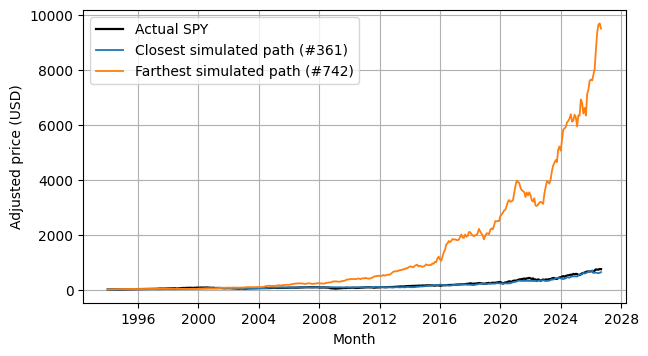

In [ ]:
d2 = np.linalg.norm(paths - p, axis=1)            # L2 distance of each path from the actual one
d2log = np.linalg.norm(np.log(paths) - np.log(p), axis=1)
best = d2.argmin()
print("closest (price):", best, d2.min(), "| closest (log):", d2log.argmin(), "| median dist:", np.median(d2))

plt.figure(figsize=(7, 3.8))
plt.plot(s.index, p, "k", lw=1.6, label="Actual SPY")
plt.plot(s.index, paths[best], lw=1.3, label=f"Closest simulated path (#{best+1})")
plt.legend(); plt.grid(True); plt.xlabel("Month"); plt.ylabel("Adjusted price (USD)")
plt.show()

farthest (price): 741 45359.1397029835 | farthest (log): 15


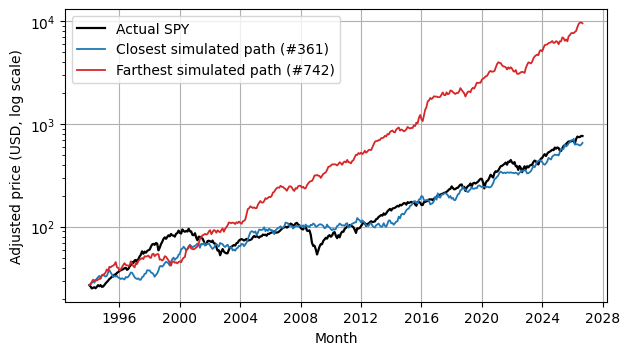

In [37]:
worst = d2.argmax()
print("farthest (price):", worst, d2.max(), "| farthest (log):", d2log.argmax())

plt.figure(figsize=(7, 3.8))
plt.plot(s.index, p, "k", lw=1.6, label="Actual SPY")
plt.plot(s.index, paths[best], lw=1.3, label=f"Closest simulated path (#{best+1})")
plt.plot(s.index, paths[worst], lw=1.3, color="tab:red", label=f"Farthest simulated path (#{worst+1})")
plt.yscale("log")
plt.legend(); plt.grid(True); plt.xlabel("Month"); plt.ylabel("Adjusted price (USD, log scale)")
plt.show()

#### 4. 99% VaR of the PNL

In [ ]:
var99 = lambda x: np.mean(x) - np.quantile(x, 0.01) #lambda calculus the 99% Value at Risk (VaR) of a given array x, defined as the difference between the mean of x and its 1st percentile.
pnl = 100*(ST - S0)

pd.DataFrame({"Value": [pnl.mean(), np.quantile(pnl, .01), var99(pnl), -np.quantile(pnl, .01)]},
             index=["Mean PNL", "1st percentile PNL", "99% VaR (mean - q01)", "-q01"]).round(2)

,Value
Mean PNL,103721.28
1st percentile PNL,7583.28
99% VaR (mean - q01),96138.00
-q01,-7583.28


#### 5. VaR as a Function of σ

##### (a)

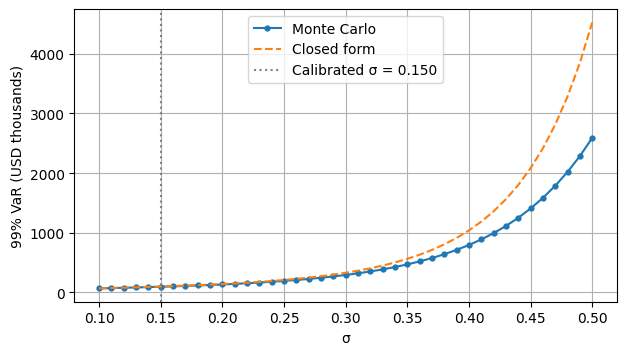

0.1 67885 69617
0.2 134031 141234
0.3 293368 330273
0.4 795333 1040193
0.5 2590365 4525573


In [30]:
grid = np.round(np.arange(0.10, 0.5001, 0.01), 2)
sweep = []
for sg in grid:
    mu_s = r.mean()/dt + sg**2/2                  # recalibrate mu for each sigma
    sweep.append(var99(100*(simulate(mu_s, sg, Z)[:, -1] - S0)))
sweep = np.array(sweep)

z = stats.norm.ppf(0.01); mT = r.mean()*n
closed = 100*S0*(np.exp(mT + grid**2*T/2) - np.exp(mT + grid*np.sqrt(T)*z))

plt.figure(figsize=(7, 3.8))
plt.plot(grid, sweep/1e3, "o-", ms=3.5, label="Monte Carlo")
plt.plot(grid, closed/1e3, "--", label="Closed form")
plt.axvline(sigma, color="gray", ls=":", label=f"Calibrated σ = {sigma:.3f}")
plt.xlabel("σ"); plt.ylabel("99% VaR (USD thousands)"); plt.grid(True); plt.legend()
plt.show()

for sg in (0.10, 0.20, 0.30, 0.40, 0.50):
    i = list(grid).index(sg); print(sg, round(sweep[i]), round(closed[i]))

##### (b)

VaR is very sensitive to σ. It grows from about $68K initially (*y-axis is in thousands so the axis runs up to about $4.5 million) at σ = 0.10 to about $2.6M at σ = 0.50. A small error in σ, or using the wrong model, changes the risk number enormously, so calibration is a major source of model risk. The effect gets stronger as sigma increases: each 0.01 step adds more to VaR than the one before, so errors in sigma are amplified most when volatility is high.

##### (c)

The curve is nonlinear and convex. Under GBM, S_T is lognormal, so VaR = 100·S₀·e^{mT}(e^{σ²T/2} − e^{zσ√T}), where z = −2.326 is the 1% normal quantile. The σ² term inside the exponential grows explosively over T ≈ 32.7 years, which bends the curve upward. For an IID Gaussian process, independent monthly shocks add up, so variances add and the total change is N(mT, σ²T). Its VaR is mT − (mT + zσ√T) = |z|·σ·√T: the drift cancels, and VaR is linear in σ. Both models start from the same Gaussian log return, but GBM turns it into a price with e^x, and that exponential step is what makes the curve convex.

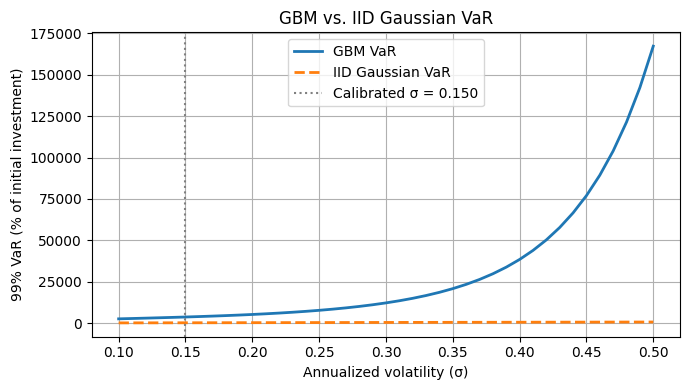

In [38]:
# Compare how 99% VaR scales with σ under the two models, both expressed as % of the initial investment
iid_gaussian_var = -z * grid * np.sqrt(T)          # IID Gaussian: VaR = |z|·σ·√T, linear in σ
gbm_var_relative = closed / (100 * S0)             # GBM closed-form VaR, divided by the initial position value

plt.figure(figsize=(7, 4))
plt.plot(grid, 100 * gbm_var_relative, label="GBM VaR", linewidth=2)
plt.plot(grid, 100 * iid_gaussian_var, "--", label="IID Gaussian VaR", linewidth=2)
plt.axvline(sigma, color="gray", linestyle=":", label=f"Calibrated σ = {sigma:.3f}")

plt.xlabel("Annualized volatility (σ)")
plt.ylabel("99% VaR (% of initial investment)")
plt.title("GBM vs. IID Gaussian VaR")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Both curves are scaled to the initial investment so they can be compared directly. The IID Gaussian VaR (|z|·σ·√T) is a straight line in σ, while the GBM VaR curves sharply upward because σ enters through the exponential. The two models agree reasonably at low σ but diverge rapidly as σ increases.

#### 6. Historical vs. Parametric VaR

##### (a)

In [31]:
print("Historical 99% VaR:", var99(r))

Historical 99% VaR: 0.11954514059956797


##### (b)

In [32]:
sim_r = np.diff(np.log(paths), axis=1).ravel()    # 1000 x 392 simulated monthly log returns, flattened
print("Parametric (MC) 99% VaR:", var99(sim_r))

Parametric (MC) 99% VaR: 0.1004494890111051


##### (c)

In [33]:
pd.DataFrame({
    "Historical": [var99(r), np.quantile(r, .01), r.min(), stats.skew(r), stats.kurtosis(r)],
    "Simulated GBM": [var99(sim_r), np.quantile(sim_r, .01), sim_r.min(), stats.skew(sim_r), stats.kurtosis(sim_r)],
}, index=["99% VaR", "1st percentile", "Min", "Skew", "Excess kurtosis"]).round(4)

,Historical,Simulated GBM
99% VaR,0.1195,0.1004
1st percentile,-0.1110,-0.0920
Min,-0.1805,-0.2171
Skew,-0.7230,-0.0010
Excess kurtosis,1.2740,-0.0104


Historical VaR (0.120) is about 19% larger than parametric VaR (0.100). The parametric figure is almost identical to a normal-distribution VaR (0.101), so GBM is effectively assuming normal returns and understates the left tail and the kurtosis

##### (d)

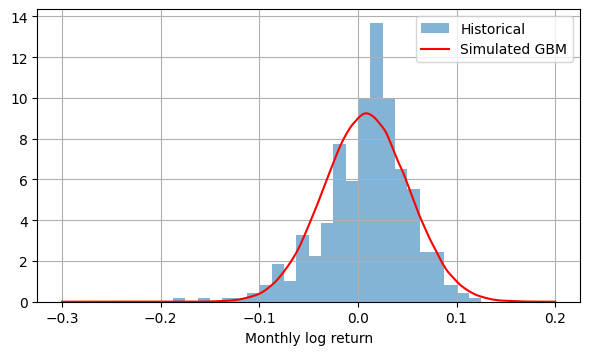

In [34]:
xs = np.linspace(-0.3, 0.2, 500)
plt.figure(figsize=(7, 3.8))
plt.hist(r, bins=40, range=(-0.3, 0.2), density=True, alpha=.55, label="Historical")
plt.plot(xs, stats.gaussian_kde(sim_r)(xs), "r", label="Simulated GBM")
plt.xlabel("Monthly log return"); plt.legend(); plt.grid(True)
plt.show()

Historical returns are negatively skewed (−0.72) with fat tails (excess kurtosis 1.27), and include crash months as bad as −18%. The simulated returns are symmetric and normal (skew ≈ 0, kurtosis ≈ 0). The historical density is more peaked in the middle and has a heavier left tail. Because skewness cubes each deviation, a few extreme months dominate it. October 2008 is the largest single contributor, but the sample contains several other crash months: Aug 1998 (Russia/LTCM, about −15%), Sep 2002 (dot-com bust, about −11%), Oct 2008 and Feb 2009 (financial crisis), Mar 2020 (COVID, about −13%), and 2022 drawdown months (around −9%). These repeated crashes, with no matching large up-months, create the heavy left tail that GBM’s normal returns cannot reproduce.

##### (e)

GBM only matches the first two moments of the data, the mean and the volatility, and implicitly assumes zero skew and zero excess kurtosis. VaR depends on the tail, which is driven by those higher moments, so GBM underestimates downside risk exactly where VaR matters: its VaR is 0.100 versus 0.120 historically. Model choice is therefore itself a risk, alongside parameter estimates. Matching more features of the data, including the observed skew (−0.72) and kurtosis (1.27), would give a more realistic tail and a VaR closer to the historical one. However, these higher moments are driven by only a few extreme months, so they are noisy to estimate. Comparing VaR across several approaches, as we did with historical and parametric VaR, further reduces reliance on any single model’s assumptions.

### Dynamic Games via Monte Carlo

#### 1. Two-Stage Problem

In [ ]:
HI = 10.0 #The upper bound of U(0, 10)

#Analytical Close-Fromed Solution 
def analytic(T):
    U = np.zeros(T + 2); U[1] = HI / 2  #E[x]=5
    for k in range(1, T + 1): #K draws left, U[k] = E[max(X, U[k-1])]
        U[k + 1] = U[k]**2 / (2*HI) + HI/2          
        # U_{n+1} = E[max(X, U_n)] = P(X<U_n)*U_n} + {Integral from {U_n} to {10}(x/10 dx)} = U_n^2/20 + 5
    thr = np.array([U[T - t] if t < T else 0.0 for t in range(T + 1)]) # threshold for continue
    #at stage t there are T−t draws still to come, you stop only if today's draw beats their value.
    return thr, U[T + 1]

#Stopping Value for Regression
def threshold_from_fit(beta):
    a, b, c = beta
    xs = np.linspace(0, HI, 20001); s_ = xs - (a + b*xs + c*xs**2)
    #edge case
    i = np.where((s_[:-1] <= 0) & (s_[1:] > 0))[0]
    if len(i) == 0: return HI if s_[-1] <= 0 else 0.0
    i = i[0]; return xs[i] - s_[i]*(xs[i+1] - xs[i])/(s_[i+1] - s_[i])

def lsmc(T, N=1_000_000, seed=2026):
    rng = np.random.default_rng(seed)
    CF = rng.uniform(0, HI, N)                       # stage T: forced stop, payoff = X_T
    coefs, thr = {}, np.zeros(T + 1)
    for t in range(T - 1, -1, -1):                   # backward induction
        X = rng.uniform(0, HI, N)                    # random draw X_t
        B = np.vander(X, 3, increasing=True)         # basis [1, x, x^2]
        beta = np.linalg.lstsq(B, CF, rcond=None)[0] # continuation value C_t(x)
        CF = np.where(X > B @ beta, X, CF)           # stop if X_t > C_t(X_t)
        coefs[t] = beta; thr[t] = threshold_from_fit(beta)
    return coefs, thr, CF.mean(), CF.std(ddof=1)/np.sqrt(N) # estimate V_0 and standard error

#Out of Sample Check
def evaluate(T, coefs, N=4_000_000, seed=2027):      # new seed, fresh paths, fixed rules (no in-sample bias)
    rng = np.random.default_rng(seed)
    CF = rng.uniform(0, HI, N)
    for t in range(T - 1, -1, -1):
        X = rng.uniform(0, HI, N)
        CF = np.where(X > np.vander(X, 3, increasing=True) @ coefs[t], X, CF)
    return CF.mean(), CF.std(ddof=1)/np.sqrt(N)

#Execution and Reporting
def run(T):
    coefs, thr, v_in, se_in = lsmc(T)
    v_out, se_out = evaluate(T, coefs)
    thr_true, v_true = analytic(T); thr[T] = 0.0
    print(f"LSMC value in-sample {v_in:.4f} (SE {se_in:.4f}) | out-of-sample {v_out:.4f} (SE {se_out:.4f}) | analytic {v_true:.4f}")
    print("value of waiting vs taking first draw (value - 5):", round(v_true - 5, 3))
    table = pd.DataFrame({"a": [coefs[t][0] for t in range(T)], "b": [coefs[t][1] for t in range(T)],
                          "c": [coefs[t][2] for t in range(T)],
                          "LSMC threshold": thr[:T], "Exact threshold": thr_true[:T]}, index=range(T))
    table.index.name = "t"
    return thr, thr_true, v_in, v_out, v_true, table

res = {}
res[2] = run(2) #2 step
res[2][-1].round(4)

LSMC value in-sample 6.9524 (SE 0.0023) | out-of-sample 6.9526 (SE 0.0012) | analytic 6.9531
value of waiting vs taking first draw (value - 5): 1.953


,a,b,c,LSMC threshold,Exact threshold
t,,,,,
0,6.2489,0.0001,-0.0000,6.2489,6.25
1,4.9876,0.0055,-0.0005,5.0013,5.00


The stopping rule is to stop at t = 1 if X₁ > 5.00, and at t = 0 if X₀ > 6.25. At t = 2 you must stop. The LSMC value is 6.9524 in-sample and 6.9526 out-of-sample, versus the analytical 6.9531 (= 5 + 6.25²/20). Thresholds and values match the analytical solution to within about 0.001.

#### 2. Ten-Stage Problem

LSMC value in-sample 8.7074 (SE 0.0013) | out-of-sample 8.7078 (SE 0.0007) | analytic 8.7075
value of waiting vs taking first draw (value - 5): 3.707


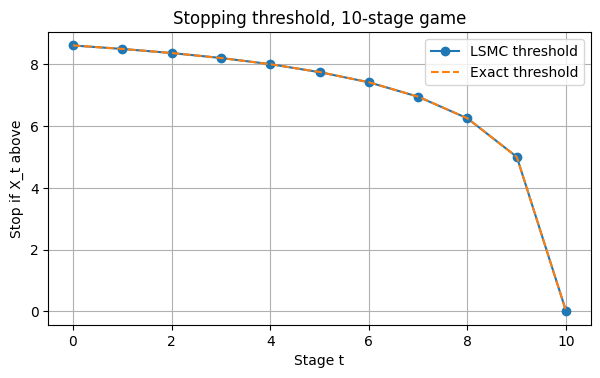

,a,b,c,LSMC threshold,Exact threshold
t,,,,,
0,8.6001,0.0051,-0.0005,8.6098,8.6110
1,8.4956,0.0006,-0.0001,8.4970,8.4982
2,8.3606,0.0006,-0.0000,8.3643,8.3645
3,8.1968,0.0011,-0.0000,8.2049,8.2030
4,8.0016,0.0000,0.0000,8.0050,8.0038
5,7.7558,-0.0016,0.0000,7.7450,7.7508
6,7.4033,0.0054,-0.0005,7.4182,7.4173
7,6.9635,-0.0064,0.0006,6.9493,6.9531
8,6.2489,0.0001,-0.0000,6.2489,6.2500


In [25]:
res[10] = run(10)
thr, thr_true = res[10][0], res[10][1]

plt.figure(figsize=(7, 3.8))
plt.plot(range(11), thr, "o-", label="LSMC threshold")
plt.plot(range(11), thr_true, "--", label="Exact threshold")
plt.xlabel("Stage t"); plt.ylabel("Stop if X_t above"); plt.title("Stopping threshold, 10-stage game")
plt.grid(True); plt.legend()
plt.show()

res[10][-1].round(4)

The thresholds fall over time: 8.61 at t = 0, then 7.75, 6.25 and 5.00 at t = 9. The maximum expected payoff is 8.7078, versus 8.7075 analytically.

#### 3. One-Hundred-Stage Problem

LSMC value in-sample 9.8139 (SE 0.0003) | out-of-sample 9.8139 (SE 0.0001) | analytic 9.8139
value of waiting vs taking first draw (value - 5): 4.814
thresholds t=0,10,50,80,99: [(0, np.float64(9.811), np.float64(9.812)), (10, np.float64(9.793), np.float64(9.792)), (50, np.float64(9.643), np.float64(9.641)), (80, np.float64(9.198), np.float64(9.199)), (99, np.float64(5.001), np.float64(5.0))]
max |LSMC - exact| over t<T: 0.006


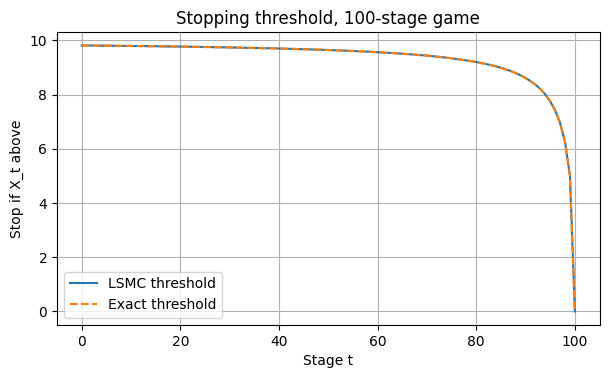

,LSMC (in-sample),LSMC (out-of-sample),Analytic,Threshold at t=0
2-stage,6.9524,6.9526,6.9531,6.2489
10-stage,8.7074,8.7078,8.7075,8.6098
100-stage,9.8139,9.8139,9.8139,9.8110


In [26]:
res[100] = run(100)
thr, thr_true = res[100][0], res[100][1]
print("thresholds t=0,10,50,80,99:", [(t, round(thr[t], 3), round(thr_true[t], 3)) for t in (0, 10, 50, 80, 99)])
print("max |LSMC - exact| over t<T:", np.abs(thr[:100] - thr_true[:100]).max().round(3))

plt.figure(figsize=(7, 3.8))
plt.plot(range(101), thr, label="LSMC threshold")
plt.plot(range(101), thr_true, "--", label="Exact threshold")
plt.xlabel("Stage t"); plt.ylabel("Stop if X_t above"); plt.title("Stopping threshold, 100-stage game")
plt.grid(True); plt.legend()
plt.show()

pd.DataFrame({"LSMC (in-sample)": [res[T][2] for T in (2, 10, 100)],
              "LSMC (out-of-sample)": [res[T][3] for T in (2, 10, 100)],
              "Analytic": [res[T][4] for T in (2, 10, 100)],
              "Threshold at t=0": [res[T][0][0] for T in (2, 10, 100)]},
             index=["2-stage", "10-stage", "100-stage"]).round(4)

The value is 9.8139 and matches the analytical value. The threshold starts at 9.81 and stays above 9 until about t = 85, then drops steeply to 5 at t = 99. Compared with 2 and 10 stages, more stages raise both the value (6.95 → 8.71 → 9.81) and the early thresholds, approaching the maximum of 10.

#### 4. Option to Wait

The option to wait is worth $V_0 - 5$: 1.95, 3.71 and 4.81 for 2, 10 and 100 stages. It grows with the horizon but at a diminishing rate, since each extra stage adds $(10-U_n)^2/20$, and the value approaches the upper bound of 10 (roughly $10 - 20/n$ for $n$ draws). The optimal threshold equals the continuation value of the remaining draws. With many stages left it is close to 10, so you are very selective. As the final stage approaches, it falls more and more steeply: 6.25 with two draws remaining, then 5 with one, then 0 at the forced stop. The time value of waiting decays to zero, like an American option’s exercise boundary near expiry. In the 100-stage plot, the threshold stays above 9 until about t = 85, then drops sharply over the last 10–15 stages. Options behave the same way near expiry: theta rapidly erodes their extrinsic (time) value. In practice, optimal exercise rules can be built the same way, using realistic return distributions (including volatility skew), option Greeks, and historical backtests from both the buyer’s and the seller’s perspective.